# Varlen Transformer (SM75 Turing / Tesla T4) — Build, Verify, Benchmark & Nsight Compute

End-to-end guide on **NVIDIA Tesla T4 (SM75)** (Google Colab / Kaggle / local CUDA GPU):
1. Verify GPU, CUDA, PyTorch environment and initialize **NVIDIA CUTLASS**.
2. Build the CUDA/CuTe extension and package a reusable `.whl` in `wheels/`.
3. Verify numerical correctness (**Forward**, **Backward**, **Flash Decoding**, and **`torch.compile` / TorchInductor**).
4. Run **Training Benchmark** (Varlen CUDA vs Batched SDPA Padded) and save `assets/training_benchmark.png`.
5. Run **Inference Benchmark** (Decode `Lq=1` & E2E Prefill/Generation) and save `assets/inference_benchmark.png`.
6. Run **NVIDIA Nsight Compute (`ncu`)** to export `.ncu-rep` reports for all 3 kernels into `Benchmark/`.

## 1. Check GPU & Prepare Source / CUTLASS

In [1]:
import os, sys, subprocess

if not os.path.isfile("setup.py") and not os.path.isdir("Varlen-Attention"):
    !git clone --recursive --depth 1 https://github.com/CBG6682/Varlen-Attention.git

if os.path.isdir("Varlen-Attention"):
    %cd Varlen-Attention
elif os.path.basename(os.getcwd()).lower() == "benchmark":
    %cd ..

print("Working directory:", os.getcwd())

import torch
print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available(), "| CUDA runtime:", torch.version.cuda)
if torch.cuda.is_available():
    print("Device:", torch.cuda.get_device_name(0), "| Capability:", torch.cuda.get_device_capability(0))

!nvidia-smi

Cloning into 'Varlen-Attention'...
remote: Enumerating objects: 36, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (34/34), done.
remote: Total 36 (delta 1), reused 18 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (36/36), 4.68 MiB | 32.14 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Submodule 'third_party/cutlass' (https://github.com/NVIDIA/cutlass.git) registered for path 'third_party/cutlass'
Cloning into '/content/Varlen-Attention/third_party/cutlass'...
remote: Enumerating objects: 46947, done.        
remote: Counting objects: 100% (676/676), done.        
remote: Compressing objects: 100% (417/417), done.        
remote: Total 46947 (delta 387), reused 261 (delta 259), pack-reused 46271 (from 3)        
Receiving objects: 100% (46947/46947), 80.03 MiB | 12.27 MiB/s, done.
Resolving deltas: 100% (34626/34626), done.
Submodule path 'third_party/cutlass': checked out 'af951046cd9cac9301d8e3e90863fd8d7edc9fa9'
/content/Varlen-At

In [2]:
%%bash
set -e
if [ ! -f "third_party/cutlass/include/cute/tensor.hpp" ]; then
    echo "Initializing NVIDIA CUTLASS submodule in third_party/cutlass..."
    git submodule update --init --depth 1 third_party/cutlass
else
    echo "CUTLASS headers already exist in third_party/cutlass/include."
fi

CUTLASS headers already exist in third_party/cutlass/include.


## 2. Build Extension & Package Wheel (`wheels/`)
If a matching `.whl` for your Python/PyTorch version already exists in `wheels/`, you can install it directly without rebuilding.

In [3]:
%%bash
set -euo pipefail
export MAX_JOBS=2
export VERBOSE=1
export TORCH_EXTENSIONS_VERBOSE=1

pip install -q ninja wheel setuptools

if ls wheels/varlen_transformer-*.whl 1>/dev/null 2>&1; then
    echo "[INFO] Found prebuilt wheel in wheels/, installing without rebuilding..."
    FORCE_REBUILD=0 python setup.py build_ext --inplace
    FORCE_REBUILD=0 python -m pip install -q --no-deps --force-reinstall wheels/varlen_transformer-*.whl
    if python -c "import varlen_transformer as vt; assert vt.HAS_CUDA_EXT" 2>/dev/null; then
        echo "[OK] Prebuilt wheel is active and matches this Python/PyTorch environment."
        ls -lh wheels/*.whl varlen_transformer/_C*.so
        exit 0
    fi
    echo "[WARN] Prebuilt wheel is incompatible with current Python/PyTorch. Rebuilding from source..."
fi

export FORCE_REBUILD=1
# Build extension (C++20 with C++17 fallback on legacy PyTorch) + verbose nvcc/cxx logs (-v)
python setup.py build_ext --inplace -v
# Package wheel (.whl) with prebuilt _C*.so into wheels/
FORCE_REBUILD=0 python -m pip wheel -v --no-deps --no-build-isolation -w wheels .
# Install package in editable mode pointing to current source
FORCE_REBUILD=0 python -m pip install -v --no-deps --no-build-isolation -e .
ls -lh wheels/*.whl varlen_transformer/_C*.so

[setup.py] Extracting prebuilt extension varlen_transformer/_C.cpython-313-x86_64-linux-gnu.so from /content/Varlen-Attention/wheels/varlen_transformer-1.0.0-py3-none-any.whl...
[setup.py] FORCE_REBUILD=1 requested: Recompiling CUDA extension from source...
[setup.py] Found CUTLASS in third_party: /content/Varlen-Attention/third_party/cutlass/include
running build_ext
building 'varlen_transformer._C' extension
creating /content/Varlen-Attention/build/temp.linux-x86_64-cpython-313/content/Varlen-Attention/src
[1/4] c++ -MMD -MF /content/Varlen-Attention/build/temp.linux-x86_64-cpython-313/content/Varlen-Attention/src/binding.o.d -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -g -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -g -fwrapv -O2 -fPIC -I/content/Varlen-Attention/include -I/content/Varlen-Attention/third_party/cutlass/include -I/usr/local/lib/python3.13/dist-packa

  Running command Preparing metadata (pyproject.toml)
  [setup.py] Prebuilt extension found: _C.cpython-313-x86_64-linux-gnu.so. Skipping compilation.
  [setup.py] (Set FORCE_REBUILD=1 to recompile from source).
  running dist_info
  creating /tmp/pip-modern-metadata-fcv6oaec/varlen_transformer.egg-info
  writing /tmp/pip-modern-metadata-fcv6oaec/varlen_transformer.egg-info/PKG-INFO
  writing dependency_links to /tmp/pip-modern-metadata-fcv6oaec/varlen_transformer.egg-info/dependency_links.txt
  writing requirements to /tmp/pip-modern-metadata-fcv6oaec/varlen_transformer.egg-info/requires.txt
  writing top-level names to /tmp/pip-modern-metadata-fcv6oaec/varlen_transformer.egg-info/top_level.txt
  writing manifest file '/tmp/pip-modern-metadata-fcv6oaec/varlen_transformer.egg-info/SOURCES.txt'
  reading manifest file '/tmp/pip-modern-metadata-fcv6oaec/varlen_transformer.egg-info/SOURCES.txt'
  adding license file 'LICENSE'
  writing manifest file '/tmp/pip-modern-metadata-fcv6oaec/varl

## 3. Correctness Verification (Correctness + Autograd + `torch.compile`)
Verifies each kernel (`mha_fwd`, `mha_bwd`, `mha_decode`), end-to-end GQA with `VarlenKVCache`, and `torch.compile(backend='inductor')`.

In [4]:
!python tests/test_correctness.py


1. Testing Varlen Forward & Backward CUDA Kernels vs Pure-PyTorch Reference

-- Case [MHA_causal_rope_odd] q_lens=[1, 17, 63, 64, 65, 129], k_lens=[1, 17, 63, 64, 65, 129], H=(8,8), causal=True, rope=True --
[PASS] MHA_causal_rope_odd.fwd_o            max_abs=0.000977  max_rel=11.625000
[PASS] MHA_causal_rope_odd.fwd_lse          max_abs=0.000001  max_rel=0.000006
[PASS] MHA_causal_rope_odd.bwd_dq           max_abs=0.000488  max_rel=87.440018
[PASS] MHA_causal_rope_odd.bwd_dk           max_abs=0.000488  max_rel=42.736530
[PASS] MHA_causal_rope_odd.bwd_dv           max_abs=0.000977  max_rel=19.347826
[PASS] MHA_causal_rope_odd.raw_vs_auto_dq   max_abs=0.000000  max_rel=0.000000
[PASS] MHA_causal_rope_odd.raw_vs_auto_dk   max_abs=0.000000  max_rel=0.000000
[PASS] MHA_causal_rope_odd.raw_vs_auto_dv   max_abs=0.000000  max_rel=0.000000

-- Case [GQA_8_2_causal_rope_offsets] q_lens=[1, 17, 63, 64, 65, 127, 257], k_lens=[1, 17, 63, 64, 65, 127, 257], H=(8,2), causal=True, rope=True --
[PASS

## 4. Training Benchmark (Forward & Forward + Backward vs `torch.compile` Baseline)
Uses **BatchedFlashGQABaselineSpeed + `torch.compile`** (TorchInductor) as the speed baseline against **VarlenFlashGQA + `torch.compile`** (via registered FakeTensors) and Eager execution.

In [5]:
!python tests/bench_training.py \
    --batch-sizes 4 8 16 \
    --max-lens 512 1024 2048 \
    --distributions skewed uniform \
    --save-plot assets/training_benchmark.png


 TRAINING BENCHMARK: Varlen CUDA vs torch.compile Baseline Speed
 Config: H_q=16, H_kv=4, D=64, causal=True, rope=True
 Primary Baseline: BatchedFlashGQABaselineSpeed + torch.compile(backend='inductor', dynamic=True)
 Custom Kernel:    VarlenFlashGQA + torch.compile(backend='inductor', dynamic=True)
W1121 14:46:01.828000 3811 torch/_inductor/utils.py:1806] [0/0_1] Not enough SMs to use max_autotune_gemm mode
W1121 14:46:46.394000 3811 torch/_dynamo/convert_frame.py:2008] [1/8] torch._dynamo hit config.recompile_limit (8)
W1121 14:46:46.394000 3811 torch/_dynamo/convert_frame.py:2008] [1/8]    function: 'forward' (/content/Varlen-Attention/varlen_transformer/model.py:589)
W1121 14:46:46.394000 3811 torch/_dynamo/convert_frame.py:2008] [1/8]    last reason: 1/2: GLOBAL_STATE changed: grad_mode 
W1121 14:46:46.394000 3811 torch/_dynamo/convert_frame.py:2008] [1/8] To log all recompilation reasons, use TORCH_LOGS="recompiles".
W1121 14:46:46.394000 3811 torch/_dynamo/convert_frame.py:2008

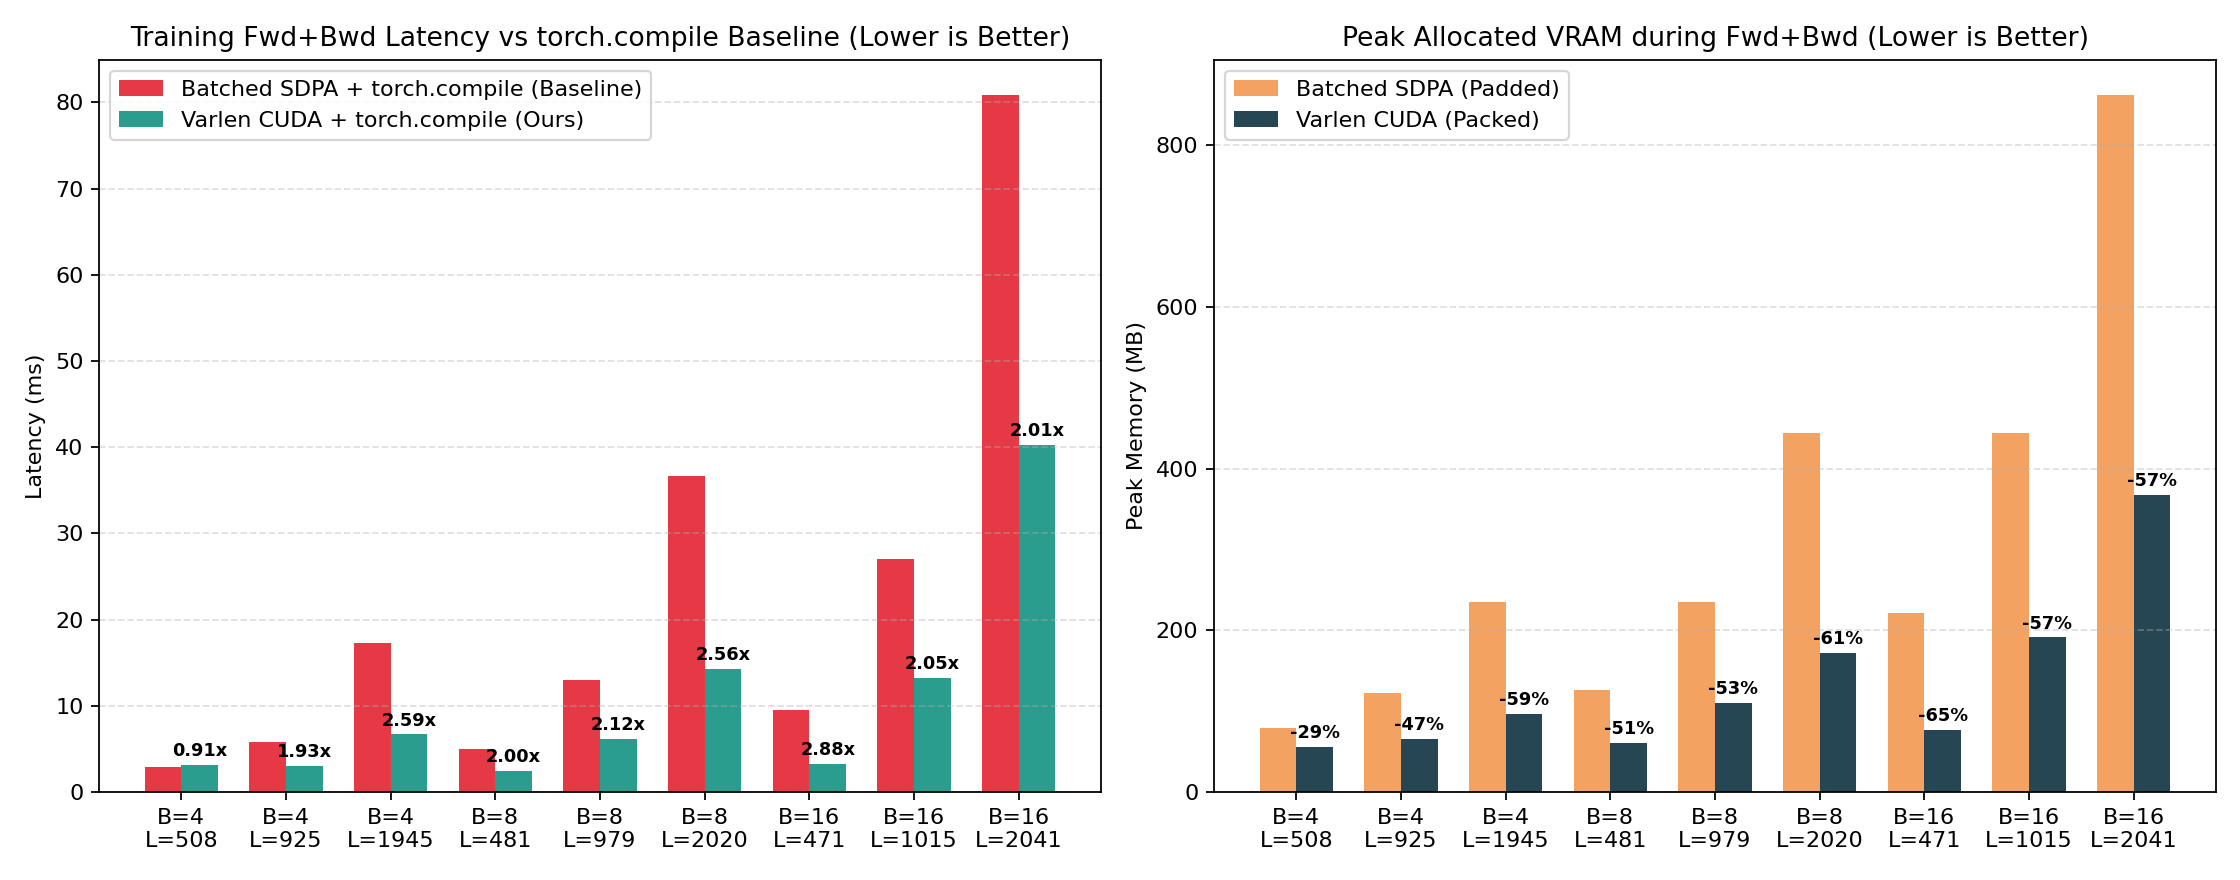

In [6]:
from IPython.display import Image, display
import os
if os.path.exists("assets/training_benchmark.png"):
    display(Image("assets/training_benchmark.png"))

## 5. Inference Benchmark (Decode `Lq=1` & End-to-End: Baseline vs Varlen Auto-Dispatch)
Uses **`torch.compile` (`SDPBackend.EFFICIENT_ATTENTION` / xFormers CUTLASS)** as the speed baseline with large configs (`H_q=32, H_kv=8`, batches up to `B=64/96` at short `L` to maximize VRAM and SM utilization). Part A measures `Lq=1` latency/bandwidth; Part B (E2E) compares **Baseline** vs **Varlen Auto-Dispatch** (automatically selecting Direct 1-Block or Split-K based on `B * H_q` and occupancy) alongside **E2E Peak VRAM**.

> **Technical Note on Baseline SDPA on T4 (`SM75`):** PyTorch SDPA with a `bool` `pad_mask` falls back to the slow `MATH` backend. Therefore, the benchmark uses an **additive `float16` mask (`0.0` / `-inf`)** and aligns the last dimension `L` to a **multiple of 8** with explicit strides `(aligned_len, 0, 0, 1)` to activate **`SDPBackend.EFFICIENT_ATTENTION`** (xFormers) for a fair baseline.

In [7]:
# Pass --e2e-quick to run a quick 5-config E2E subset
!python tests/bench_inference.py \
    --batch-sizes 1 8 32 64 \
    --max-lens 128 256 1024 2048 4096 \
    --num-heads-q 32 \
    --num-heads-kv 8 \
    --distributions skewed uniform \
    --gen-steps 32 \
    --save-plot assets/inference_benchmark.png


 PART A: Microbenchmark Decode Attention L_q=1 (Cold L2 - Speed & Bandwidth Only)
 Config: H_q=32, H_kv=8, D=64, rope=True, clear_l2=True
 Baseline Speed: Batched SDPA (SDPBackend.EFFICIENT_ATTENTION) + torch.compile(dynamic=False)
 Custom Kernel:  Varlen Adaptive Auto-Dispatch (+ torch.compile)
[INFO] Part A SDPA Backend verified: SDPBackend.EFFICIENT_ATTENTION (choice=2)
W1121 14:48:32.285000 4521 torch/_dynamo/convert_frame.py:2008] [0/8] torch._dynamo hit config.recompile_limit (8)
W1121 14:48:32.285000 4521 torch/_dynamo/convert_frame.py:2008] [0/8]    function: '_c_batched_dec' (/content/Varlen-Attention/tests/bench_inference.py:339)
W1121 14:48:32.285000 4521 torch/_dynamo/convert_frame.py:2008] [0/8]    last reason: 0/7: tensor 'k_exp' size mismatch at index 2. expected 1000, actual 1976
W1121 14:48:32.285000 4521 torch/_dynamo/convert_frame.py:2008] [0/8] To log all recompilation reasons, use TORCH_LOGS="recompiles".
W1121 14:48:32.285000 4521 torch/_dynamo/convert_frame.py:2

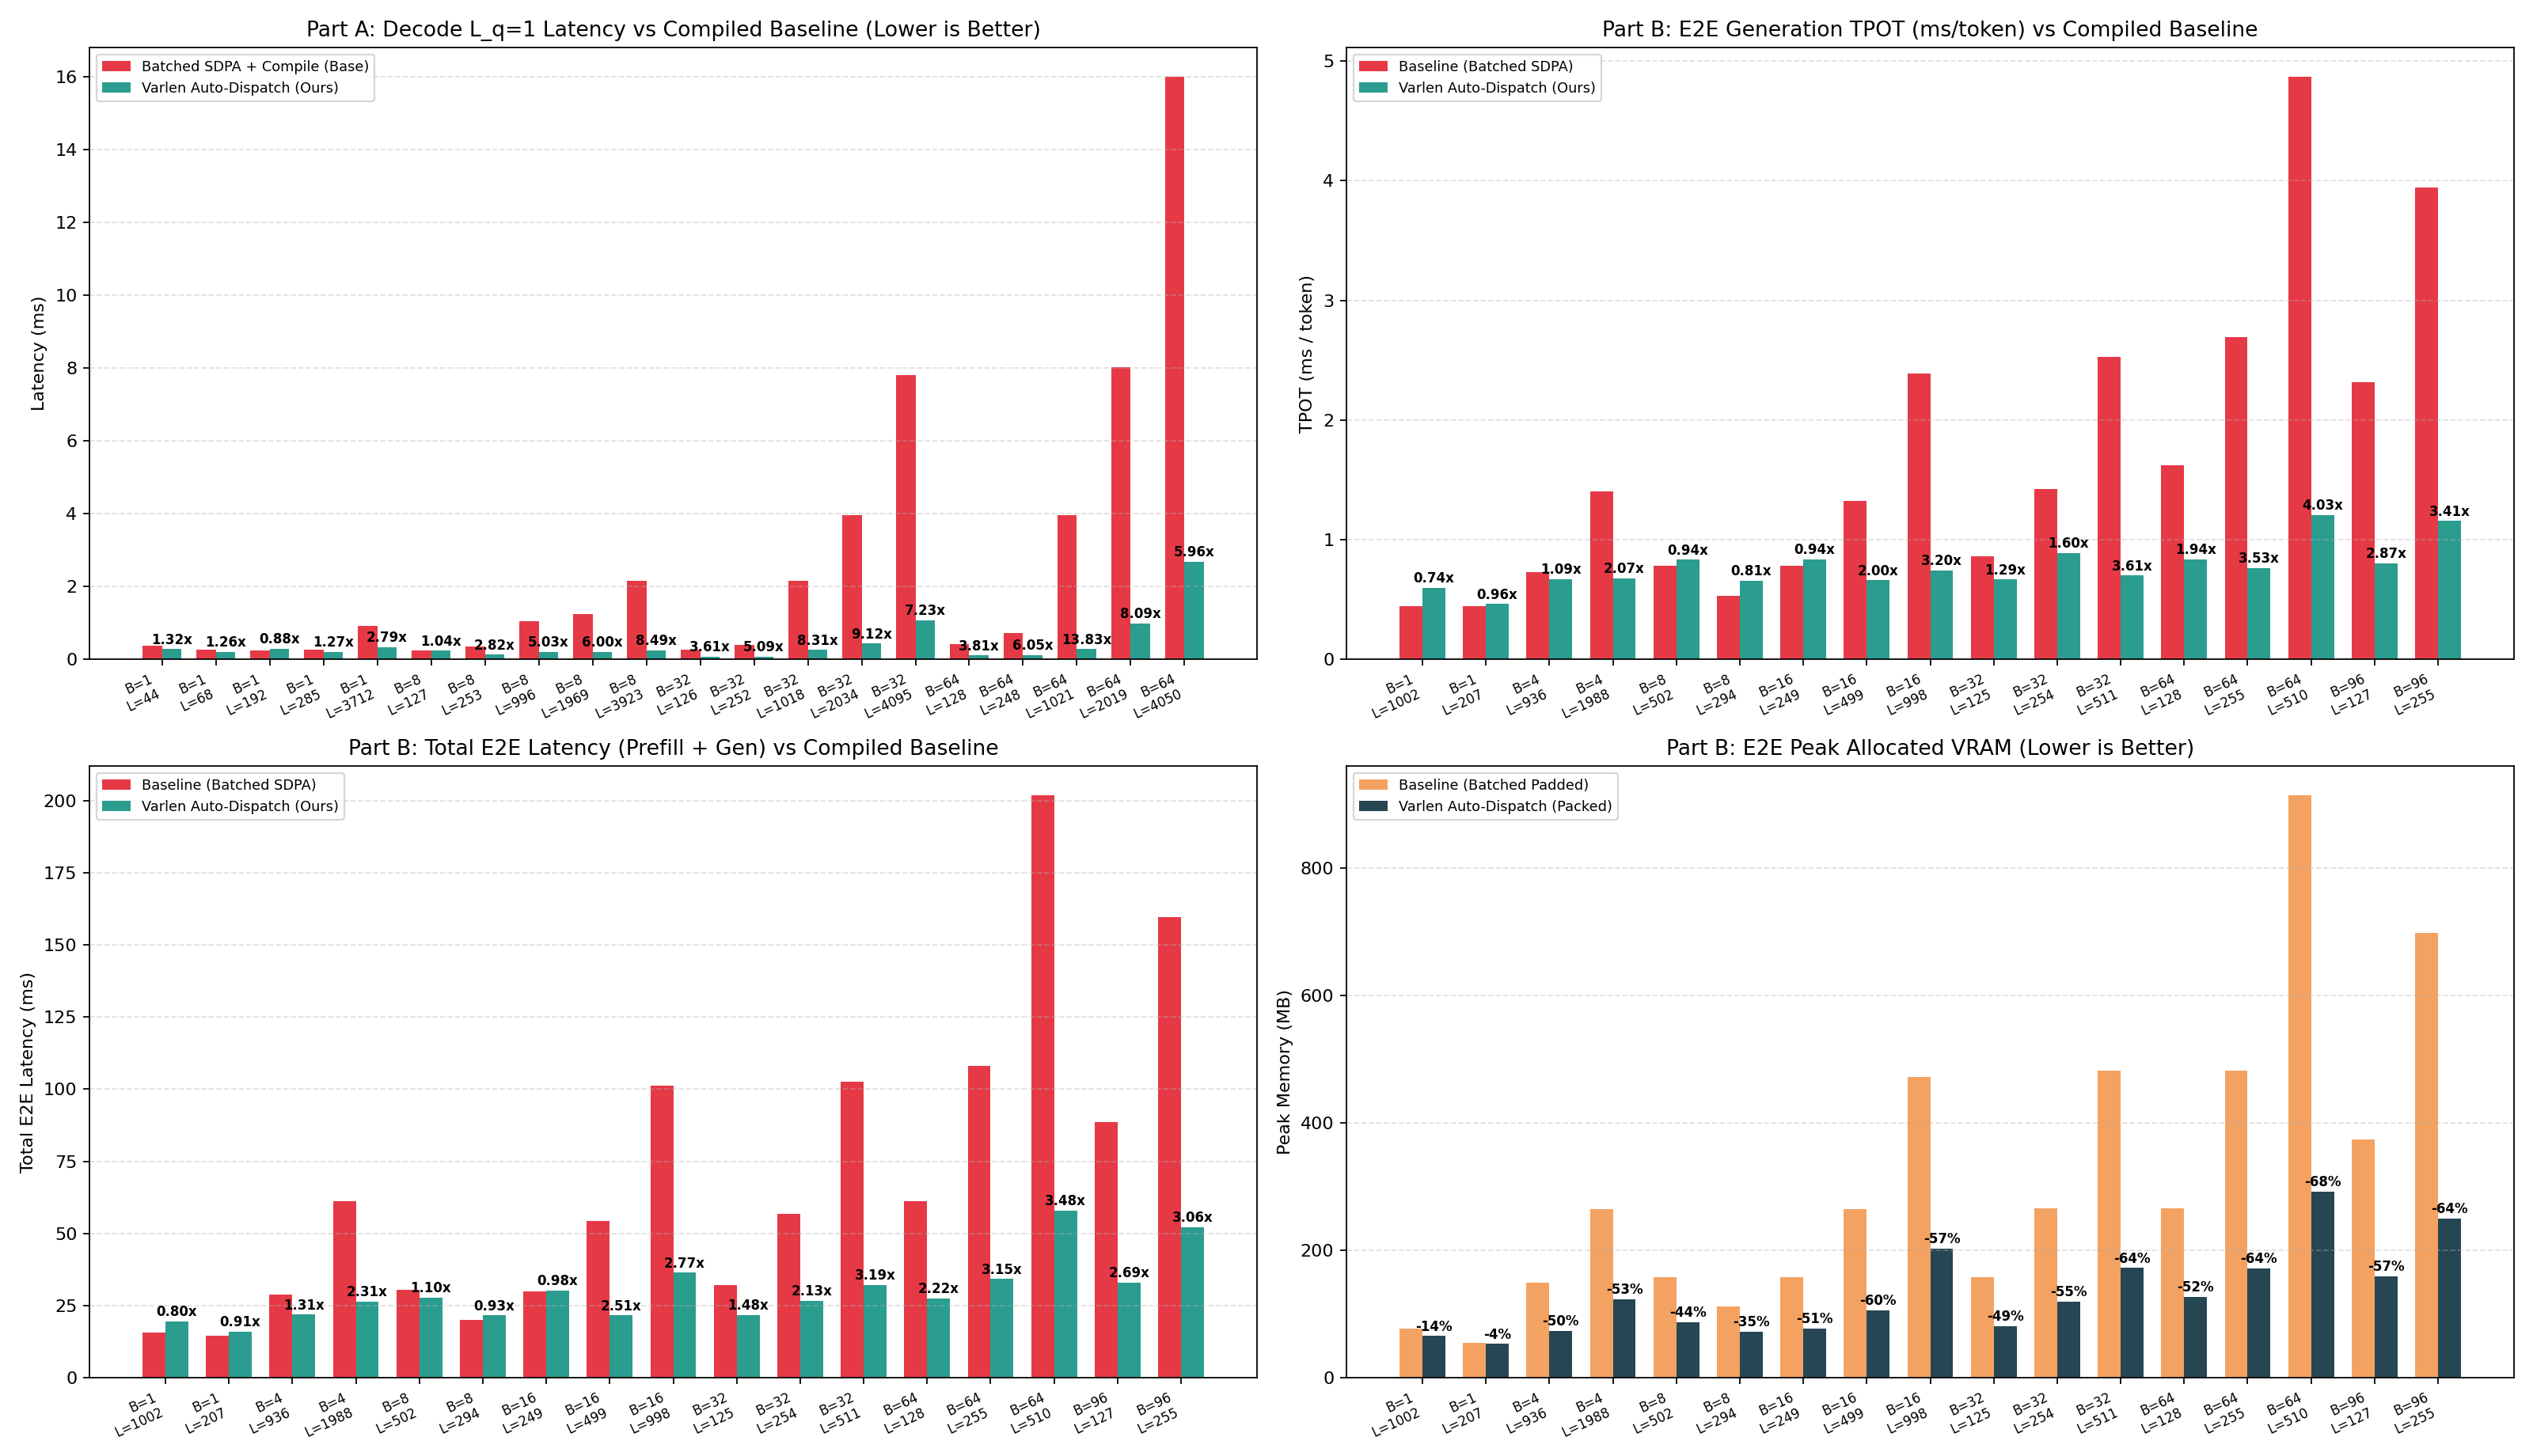

In [8]:
from IPython.display import Image, display
import os
if os.path.exists("assets/inference_benchmark.png"):
    display(Image("assets/inference_benchmark.png"))

## 6. Nsight Compute Profiling (`.ncu-rep` in `Benchmark/`)
Collects hardware performance counters (`SM Throughput`, `DRAM Bandwidth`, `Achieved Occupancy`, `Register/Thread`) with **embedded CUDA/C++ source (`--import-source yes`)** into 3 report files:
- `Benchmark/mha_fwd.ncu-rep` (4 scenarios: `short_b1`, `short_b16`, `skewed_b4`, `long_b1`)
- `Benchmark/mha_bwd.ncu-rep` (4 scenarios: `short_b1`, `short_b16`, `skewed_b4`, `long_b1`)
- `Benchmark/mha_decode.ncu-rep` (all 4 scenarios + Direct 1-Block vs Split-K comparison on `skewed_b4`)

> Note: On some cloud containers without hardware counter permissions for `ncu`, the command may report `ERR_NVGPUCTRPERM`.

In [9]:
%%bash
set -e
if ! command -v ncu &> /dev/null; then
    echo "[INFO] NVIDIA Nsight Compute (ncu) not found in PATH."
    exit 0
fi

NCU_SCRIPT='import sys, torch, varlen_transformer as vt
mode = sys.argv[1]
dev = torch.device("cuda")
cases = [
    ("short_b1", [128]),
    ("short_b16", [128] * 16),
    ("skewed_b4", [256, 512, 1024, 2048]),
    ("long_b1", [4096]),
]
rope = vt.RotaryPositionalEmbedding(64, max_seq_len=4200, device=dev)
cos, sin = rope.get_cos_sin(device=dev, dtype=torch.float16)
for cname, lens in cases:
    cu = torch.tensor([0] + torch.cumsum(torch.tensor(lens), 0).tolist(), dtype=torch.int32, device=dev)
    total_l = int(cu[-1].item())
    max_l = max(lens)
    B = len(lens)
    k = torch.randn((4, total_l, 64), device=dev, dtype=torch.float16)
    v = torch.randn((4, total_l, 64), device=dev, dtype=torch.float16)
    if mode == "fwd":
        q = torch.randn((16, total_l, 64), device=dev, dtype=torch.float16)
        vt.fused_mha_varlen_fwd(q, k, v, cu, cu, max_l, cos=cos, sin=sin, is_causal=True)
    elif mode == "bwd":
        q = torch.randn((16, total_l, 64), device=dev, dtype=torch.float16)
        o, lse = vt.fused_mha_varlen_fwd(q, k, v, cu, cu, max_l, cos=cos, sin=sin, is_causal=True)
        do = torch.randn_like(o)
        vt.fused_mha_varlen_bwd(do, q, k, v, o, lse, cu, cu, None, max_l, cos=cos, sin=sin, is_causal=True)
    elif mode == "decode":
        qd = torch.randn((16, B, 64), device=dev, dtype=torch.float16)
        vt.fused_mha_varlen_decode(qd, k, v, cu, max_l, cos=cos, sin=sin)
        if cname == "skewed_b4":
            vt.fused_mha_varlen_decode(qd, k, v, cu, max_l, cos=cos, sin=sin, use_splitk=False)
            vt.fused_mha_varlen_decode(qd, k, v, cu, max_l, cos=cos, sin=sin, use_splitk=True)
torch.cuda.synchronize()'

echo "$NCU_SCRIPT" > Benchmark/_ncu_profile_target.py

for MODE in fwd bwd decode; do
    echo "=== Profiling mha_${MODE} (multi-case + embedded source) ==="
    ncu --set full --import-source yes --source-folders .,src,include -k "regex:kernel_fused_mha_varlen_${MODE}" -f -o "Benchmark/mha_${MODE}" python Benchmark/_ncu_profile_target.py "${MODE}" || true
done

rm -f Benchmark/_ncu_profile_target.py
ls -lh Benchmark/*.ncu-rep 2>/dev/null || echo "No .ncu-rep files generated."

=== Profiling mha_fwd (multi-case + embedded source) ===
==PROF== Connected to process 5709 (/usr/bin/python3.13)
==PROF== Profiling "kernel_fused_mha_varlen_fwd": 0%....50%....100% - 33 passes
==PROF== Profiling "kernel_fused_mha_varlen_fwd": 0%....50%....100% - 33 passes
==PROF== Profiling "kernel_fused_mha_varlen_fwd": 0%....50%....100% - 33 passes
==PROF== Profiling "kernel_fused_mha_varlen_fwd": 0%....50%....100% - 33 passes
==PROF== Disconnected from process 5709
==PROF== Report: /content/Varlen-Attention/Benchmark/mha_fwd.ncu-rep
=== Profiling mha_bwd (multi-case + embedded source) ===
==PROF== Connected to process 6039 (/usr/bin/python3.13)
==PROF== Profiling "kernel_fused_mha_varlen_bwd": 0%....50%....100% - 33 passes
==PROF== Profiling "kernel_fused_mha_varlen_bwd": 0%....50%....100% - 33 passes
==PROF== Profiling "kernel_fused_mha_varlen_bwd": 0%....50%....100% - 33 passes
==PROF== Profiling "kernel_fused_mha_varlen_bwd": 0%....50%....100% - 33 passes
==PROF== Disconnected f